# EPL Match Prediction — Eksperimen Final

Notebook ini disusun mengikuti arahan review dosen dan keputusan metodologi yang telah ditetapkan:

- Target: `H` (Home Win), `D` (Draw), `A` (Away Win), diturunkan dari skor akhir.
- Fitur: 4 statistik untuk kandang, 4 untuk tandang, dan 4 selisih = **12 fitur**.
- Riwayat: maksimal 5 pertandingan terakhir untuk setiap tim, baik kandang maupun tandang.
- Syarat: masing-masing tim harus memiliki minimal 3 pertandingan sebelumnya.
- Data split: train 2018/19–2023/24, validation 2024/25, final test 2025/26.
- Pemilihan konfigurasi: berdasarkan Macro F1 pada validation; Log Loss menjadi pertimbangan kedua.
- Model final untuk laporan: dilatih ulang dengan train + validation dan diuji pada 2025/26.
- Model produksi live 2026/27: dilatih dengan data sampai 2025/26 lalu dibekukan (fixed model).

**Catatan penanganan waktu:** file sumber utama menggunakan tanggal pertandingan. Untuk mencegah pertandingan lain pada tanggal yang sama ikut menjadi riwayat, seluruh fitur untuk satu tanggal dibentuk terlebih dahulu, baru hasil pertandingan tanggal tersebut ditambahkan ke riwayat tim. Ini adalah aturan konservatif karena waktu selesai pertandingan tidak tersedia secara konsisten.

**Catatan SOT kosong:** nilai SOT kosong tidak diubah menjadi nol. Rata-rata SOT dihitung dari nilai valid dalam maksimal lima laga. Jika seluruh nilai SOT dalam jendela tersebut kosong, nilainya tetap `NaN` dan ditangani dengan median imputation yang di-fit hanya pada data training melalui Pipeline Scikit-learn.

> Letakkan sembilan file CSV (`E0_1819.csv` sampai `E0_2627.csv`) di `ml-service/data/raw/`. Jalankan cell dari atas ke bawah.

In [1]:
# 1. Imports dan konfigurasi
from pathlib import Path
from collections import defaultdict, deque
from itertools import product
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    log_loss,
)

RANDOM_STATE = 42
SEASON_CODES = ["1819", "1920", "2021", "2122", "2223", "2324", "2425", "2526", "2627"]
TRAIN_SEASONS = ["1819", "1920", "2021", "2122", "2223", "2324"]
VALID_SEASONS = ["2425"]
TEST_SEASONS = ["2526"]
LIVE_SEASONS = ["2627"]

CLASS_ORDER = ["H", "D", "A"]
HISTORY_WINDOW = 5
MIN_HISTORY_MATCHES = 3
FEATURE_SUFFIXES = ["gf_5", "ga_5", "pts_5", "sot_5"]
FEATURE_COLUMNS = (
    [f"H_{c}" for c in FEATURE_SUFFIXES]
    + [f"A_{c}" for c in FEATURE_SUFFIXES]
    + [f"diff_{c}" for c in FEATURE_SUFFIXES]
)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Fitur:", len(FEATURE_COLUMNS), FEATURE_COLUMNS)
assert len(FEATURE_COLUMNS) == 12

Matplotlib is building the font cache; this may take a moment.


pandas: 2.3.3
numpy: 2.4.6
scikit-learn: 1.9.1
Fitur: 12 ['H_gf_5', 'H_ga_5', 'H_pts_5', 'H_sot_5', 'A_gf_5', 'A_ga_5', 'A_pts_5', 'A_sot_5', 'diff_gf_5', 'diff_ga_5', 'diff_pts_5', 'diff_sot_5']


## 2. Menemukan lokasi dataset

Notebook dapat dijalankan dari folder `ml-service/notebooks`, `ml-service`, atau root repository. Kode akan mencari folder `data/raw` yang berisi seluruh sembilan CSV.

In [2]:
# 2. Resolve lokasi data dan artefak
CSV_NAMES = [f"E0_{season}.csv" for season in SEASON_CODES]
DATA_DIR_CANDIDATES = [
    Path("../data/raw"),
    Path("data/raw"),
    Path("ml-service/data/raw"),
    Path("../../ml-service/data/raw"),
    Path("."),  # fallback jika CSV sementara diletakkan bersama notebook
]

DATA_DIR = None
for candidate in DATA_DIR_CANDIDATES:
    if all((candidate / filename).is_file() for filename in CSV_NAMES):
        DATA_DIR = candidate.resolve()
        break

if DATA_DIR is None:
    checked = "\n".join(str(p.resolve()) for p in DATA_DIR_CANDIDATES)
    raise FileNotFoundError(
        "Tidak menemukan seluruh CSV musim 1819–2627.\n"
        "Letakkan E0_1819.csv ... E0_2627.csv di ml-service/data/raw/.\n"
        f"Lokasi yang diperiksa:\n{checked}"
    )

ML_SERVICE_DIR = DATA_DIR.parent.parent if DATA_DIR.name == "raw" else Path.cwd().resolve()
ARTIFACT_DIR = ML_SERVICE_DIR / "artifacts"
PROCESSED_DIR = ML_SERVICE_DIR / "data" / "processed"
REPORT_DIR = ARTIFACT_DIR / "reports"

for directory in [ARTIFACT_DIR, PROCESSED_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", DATA_DIR)
print("Artifact directory:", ARTIFACT_DIR)

Dataset directory: D:\Skripsi\epl-prediction-system\ml-service\data\raw
Artifact directory: D:\Skripsi\epl-prediction-system\ml-service\artifacts


## 3. Memuat dan memeriksa dataset

Label penelitian diturunkan dari `FTHG` dan `FTAG`. Kolom `FTR` dari sumber digunakan untuk pemeriksaan konsistensi, bukan sebagai satu-satunya dasar label. Baris yang belum memiliki skor akhir dikeluarkan dari data pertandingan selesai.

In [3]:
# 3. Load sembilan musim dan preprocessing dasar
required_columns = ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]
frames = []
load_summary = []

for season in SEASON_CODES:
    path = DATA_DIR / f"E0_{season}.csv"
    raw = pd.read_csv(path, encoding="latin-1")

    missing_required = [c for c in required_columns if c not in raw.columns]
    if missing_required:
        raise ValueError(f"{path.name} tidak memiliki kolom wajib: {missing_required}")

    # HST/AST boleh memiliki nilai kosong. Jika kolom tidak tersedia, isi NaN,
    # bukan nol, agar tidak mengarang statistik tembakan tepat sasaran.
    for optional_col in ["HST", "AST", "FTR"]:
        if optional_col not in raw.columns:
            raw[optional_col] = np.nan

    selected = raw[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "HST", "AST"]].copy()
    selected["Season"] = season
    selected["SourceRow"] = np.arange(len(selected))
    selected["Date"] = pd.to_datetime(selected["Date"], dayfirst=True, errors="coerce").dt.normalize()

    for col in ["FTHG", "FTAG", "HST", "AST"]:
        selected[col] = pd.to_numeric(selected[col], errors="coerce")

    selected["HomeTeam"] = selected["HomeTeam"].astype("string").str.strip()
    selected["AwayTeam"] = selected["AwayTeam"].astype("string").str.strip()
    selected["FTR"] = selected["FTR"].astype("string").str.strip().str.upper()

    before = len(selected)
    selected = selected.dropna(subset=["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]).copy()
    selected = selected[
        selected["HomeTeam"].ne("") & selected["AwayTeam"].ne("")
    ].copy()

    # Turunkan target dari skor akhir.
    selected["Target"] = np.select(
        [selected["FTHG"] > selected["FTAG"], selected["FTHG"] == selected["FTAG"]],
        ["H", "D"],
        default="A",
    )

    # Periksa konsistensi FTR sumber terhadap label yang diturunkan dari skor.
    has_source_ftr = selected["FTR"].notna() & selected["FTR"].ne("") & selected["FTR"].ne("<NA>")
    mismatch = has_source_ftr & selected["FTR"].ne(selected["Target"])
    if mismatch.any():
        sample = selected.loc[mismatch, ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "Target"]].head(10)
        display(sample)
        raise ValueError(f"Ditemukan {int(mismatch.sum())} ketidaksesuaian FTR dengan skor pada musim {season}.")

    selected["MatchID"] = selected["Season"] + "_" + selected["SourceRow"].astype(str)
    load_summary.append({
        "Season": season,
        "Rows_in_CSV": before,
        "Completed_matches_kept": len(selected),
        "Rows_removed": before - len(selected),
        "Missing_HST": int(selected["HST"].isna().sum()),
        "Missing_AST": int(selected["AST"].isna().sum()),
    })
    frames.append(selected)

data = pd.concat(frames, ignore_index=True)

# Hilangkan duplikasi fixture identik pada tanggal yang sama.
duplicate_mask = data.duplicated(subset=["Date", "HomeTeam", "AwayTeam"], keep="first")
duplicate_count = int(duplicate_mask.sum())
if duplicate_count:
    print("Duplikasi fixture dihapus:", duplicate_count)
    data = data.loc[~duplicate_mask].copy()

# Urutan kronologis; fitur tanggal yang sama akan dibentuk sebelum hasil tanggal tersebut ditambahkan.
data = data.sort_values(["Date", "Season", "SourceRow"], kind="stable").reset_index(drop=True)

load_summary_df = pd.DataFrame(load_summary)
display(load_summary_df)
print("Total pertandingan selesai:", len(data))
print("Distribusi target:")
display(data["Target"].value_counts().reindex(CLASS_ORDER, fill_value=0).to_frame("Jumlah"))
print("Distribusi target (proporsi):")
display(data["Target"].value_counts(normalize=True).reindex(CLASS_ORDER, fill_value=0).round(4).to_frame("Proporsi"))

,Season,Rows_in_CSV,Completed_matches_kept,Rows_removed,Missing_HST,Missing_AST
0,1819,380,380,0,0,0
1,1920,380,380,0,0,0
2,2021,380,380,0,0,0
3,2122,380,380,0,0,0
4,2223,380,380,0,0,0
5,2324,380,380,0,0,0
6,2425,380,380,0,0,0
7,2526,380,380,0,0,0
8,2627,60,60,0,0,0


Total pertandingan selesai: 3100
Distribusi target:


,Jumlah
Target,
H,1359
D,719
A,1022


Distribusi target (proporsi):


,Proporsi
Target,
H,0.4384
D,0.2319
A,0.3297


## 4. Membentuk fitur historis 12 kolom

Setiap tim menggunakan maksimal lima pertandingan terakhir tanpa membedakan kandang/tandang. Statistik pertandingan pada tanggal yang sama tidak dimasukkan ke riwayat satu sama lain: seluruh fitur pada tanggal tersebut dibentuk dahulu, baru hasil tanggal itu ditambahkan ke riwayat. Sampel hanya digunakan jika tim kandang dan tandang masing-masing memiliki minimal tiga pertandingan sebelumnya.

In [4]:
# 4. Feature engineering kronologis tanpa data leakage
team_history = defaultdict(lambda: deque(maxlen=HISTORY_WINDOW))
feature_records = []


def summarize_recent_history(history_items):
    """Ringkas maksimal 5 pertandingan terakhir; SOT mengabaikan nilai NaN."""
    recent = list(history_items)[-HISTORY_WINDOW:]
    if len(recent) < MIN_HISTORY_MATCHES:
        return None

    gf_values = [item["GF"] for item in recent]
    ga_values = [item["GA"] for item in recent]
    points_values = [item["Points"] for item in recent]
    sot_values = [item["SOT"] for item in recent if pd.notna(item["SOT"])]

    return {
        "gf_5": float(np.mean(gf_values)),
        "ga_5": float(np.mean(ga_values)),
        "pts_5": float(np.mean(points_values)),
        "sot_5": float(np.mean(sot_values)) if sot_values else np.nan,
        "n_prev": len(recent),
        "n_sot_valid": len(sot_values),
    }


# Group per tanggal: fitur dibuat terlebih dahulu untuk seluruh pertandingan pada tanggal itu.
for match_date, day_matches in data.groupby("Date", sort=True):
    day_matches = day_matches.sort_values(["Season", "SourceRow"], kind="stable")

    for row in day_matches.itertuples(index=False):
        home_history = team_history[row.HomeTeam]
        away_history = team_history[row.AwayTeam]

        home_stats = summarize_recent_history(home_history)
        away_stats = summarize_recent_history(away_history)

        # Minimal 3 pertandingan sebelumnya untuk kedua tim.
        if home_stats is None or away_stats is None:
            continue

        record = {
            "MatchID": row.MatchID,
            "Date": row.Date,
            "Season": row.Season,
            "HomeTeam": row.HomeTeam,
            "AwayTeam": row.AwayTeam,
            "Target": row.Target,
            "H_n_prev": home_stats["n_prev"],
            "A_n_prev": away_stats["n_prev"],
            "H_n_sot_valid": home_stats["n_sot_valid"],
            "A_n_sot_valid": away_stats["n_sot_valid"],
        }

        for suffix in FEATURE_SUFFIXES:
            h_value = home_stats[suffix]
            a_value = away_stats[suffix]
            record[f"H_{suffix}"] = h_value
            record[f"A_{suffix}"] = a_value
            record[f"diff_{suffix}"] = (
                h_value - a_value if pd.notna(h_value) and pd.notna(a_value) else np.nan
            )

        feature_records.append(record)

    # Update riwayat setelah semua fitur pada tanggal ini selesai dibentuk.
    for row in day_matches.itertuples(index=False):
        home_points = 3 if row.FTHG > row.FTAG else (1 if row.FTHG == row.FTAG else 0)
        away_points = 3 if row.FTAG > row.FTHG else (1 if row.FTAG == row.FTHG else 0)

        team_history[row.HomeTeam].append({
            "GF": float(row.FTHG),
            "GA": float(row.FTAG),
            "Points": float(home_points),
            "SOT": row.HST if pd.notna(row.HST) else np.nan,
        })
        team_history[row.AwayTeam].append({
            "GF": float(row.FTAG),
            "GA": float(row.FTHG),
            "Points": float(away_points),
            "SOT": row.AST if pd.notna(row.AST) else np.nan,
        })

feature_df = pd.DataFrame(feature_records)
if feature_df.empty:
    raise ValueError("Tidak ada sampel yang memenuhi minimal 3 pertandingan sebelumnya untuk kedua tim.")

missing_feature_cols = [c for c in FEATURE_COLUMNS if c not in feature_df.columns]
if missing_feature_cols:
    raise RuntimeError(f"Kolom fitur tidak terbentuk: {missing_feature_cols}")

print("Jumlah sampel setelah syarat minimal riwayat:", len(feature_df))
print("Jumlah fitur model:", len(FEATURE_COLUMNS))
print("Missing value pada fitur:")
display(feature_df[FEATURE_COLUMNS].isna().sum().to_frame("Missing"))
print("Sampel per musim:")
display(feature_df.groupby("Season").size().reindex(SEASON_CODES, fill_value=0).to_frame("Jumlah"))

# Simpan dataset fitur untuk audit/reproduksibilitas lokal.
feature_df.to_csv(PROCESSED_DIR / "match_features_12.csv", index=False)
print("Disimpan:", PROCESSED_DIR / "match_features_12.csv")

Jumlah sampel setelah syarat minimal riwayat: 3035
Jumlah fitur model: 12
Missing value pada fitur:


,Missing
H_gf_5,0
H_ga_5,0
H_pts_5,0
H_sot_5,0
A_gf_5,0
A_ga_5,0
A_pts_5,0
A_sot_5,0
diff_gf_5,0
diff_ga_5,0


Sampel per musim:


,Jumlah
Season,
1819,350
1920,371
2021,374
2122,377
2223,377
2324,377
2425,377
2526,377
2627,55


Disimpan: D:\Skripsi\epl-prediction-system\ml-service\data\processed\match_features_12.csv


## 5. Membagi data berdasarkan musim

Pembagian ini tidak dilakukan secara acak. Musim 2024/25 hanya untuk pemilihan konfigurasi; musim 2025/26 hanya untuk pengujian final. Baris musim 2026/27 tidak digunakan untuk training atau final testing.

In [5]:
# 5. Temporal split
train = feature_df[feature_df["Season"].isin(TRAIN_SEASONS)].copy()
valid = feature_df[feature_df["Season"].isin(VALID_SEASONS)].copy()
test = feature_df[feature_df["Season"].isin(TEST_SEASONS)].copy()
live_completed = feature_df[feature_df["Season"].isin(LIVE_SEASONS)].copy()

for split_name, split_df in [("train", train), ("validation", valid), ("test", test)]:
    if split_df.empty:
        raise ValueError(f"Split {split_name} kosong. Periksa data CSV dan pembentukan fitur.")

X_train = train[FEATURE_COLUMNS].copy()
y_train = train["Target"].copy()
X_valid = valid[FEATURE_COLUMNS].copy()
y_valid = valid["Target"].copy()
X_test = test[FEATURE_COLUMNS].copy()
y_test = test["Target"].copy()

# Imputer median tidak boleh menerima kolom yang seluruh nilainya kosong pada training.
all_missing_training = [c for c in FEATURE_COLUMNS if X_train[c].isna().all()]
if all_missing_training:
    raise ValueError(
        "Fitur berikut seluruhnya kosong pada data training dan tidak dapat diimputasi: "
        f"{all_missing_training}. Periksa ketersediaan kolom HST/AST pada CSV."
    )

split_summary = pd.DataFrame([
    {"Split": "Train", "Seasons": ", ".join(TRAIN_SEASONS), "Rows": len(train)},
    {"Split": "Validation", "Seasons": ", ".join(VALID_SEASONS), "Rows": len(valid)},
    {"Split": "Final Test", "Seasons": ", ".join(TEST_SEASONS), "Rows": len(test)},
    {"Split": "Live completed data (not retrospective evaluation)", "Seasons": ", ".join(LIVE_SEASONS), "Rows": len(live_completed)},
])
display(split_summary)
print("Distribusi kelas training:")
display(y_train.value_counts().reindex(CLASS_ORDER, fill_value=0).to_frame("Jumlah"))
print("Distribusi kelas validation:")
display(y_valid.value_counts().reindex(CLASS_ORDER, fill_value=0).to_frame("Jumlah"))
print("Distribusi kelas test:")
display(y_test.value_counts().reindex(CLASS_ORDER, fill_value=0).to_frame("Jumlah"))

,Split,Seasons,Rows
0,Train,"1819, 1920, 2021, 2122, 2223, 2324",2226
1,Validation,2425,377
2,Final Test,2526,377
3,Live completed data (not retrospective evaluat...,2627,55


Distribusi kelas training:


,Jumlah
Target,
H,992
D,492
A,742


Distribusi kelas validation:


,Jumlah
Target,
H,154
D,92
A,131


Distribusi kelas test:


,Jumlah
Target,
H,159
D,104
A,114


## 6. Fungsi model, probabilitas, dan metrik

Median imputation dilakukan di dalam Pipeline sehingga nilai median hanya dipelajari dari split training pada masing-masing tahap. Logistic Regression menggunakan StandardScaler setelah imputasi. Probabilitas selalu disejajarkan ke urutan kelas `H`, `D`, `A` agar tidak salah label saat ditampilkan oleh website.

In [6]:
# 6. Model pipeline dan helper evaluasi

def make_lr_model(params=None):
    params = params or {}
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=5000,
            solver="lbfgs",
            random_state=RANDOM_STATE,
            **params,
        )),
    ])


def make_rf_model(params=None):
    params = params or {}
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )),
    ])


def predict_proba_in_class_order(model, X):
    raw_proba = model.predict_proba(X)
    model_classes = model.named_steps["classifier"].classes_
    aligned = np.zeros((len(X), len(CLASS_ORDER)), dtype=float)
    class_to_index = {label: idx for idx, label in enumerate(CLASS_ORDER)}

    for source_idx, label in enumerate(model_classes):
        if label in class_to_index:
            aligned[:, class_to_index[label]] = raw_proba[:, source_idx]

    row_sums = aligned.sum(axis=1, keepdims=True)
    if np.any(row_sums == 0):
        raise ValueError("Model menghasilkan baris probabilitas dengan jumlah nol.")
    return aligned / row_sums


def calculate_metrics(y_true, y_pred, probabilities):
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0,
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "log_loss": log_loss(y_true, probabilities, labels=CLASS_ORDER),
    }


def evaluate_model(model, X, y):
    prediction = model.predict(X)
    probabilities = predict_proba_in_class_order(model, X)
    metrics = calculate_metrics(y, prediction, probabilities)
    return metrics, prediction, probabilities


def evaluate_majority_baseline(y_fit, y_eval):
    """Baseline kelas mayoritas; prior kelas training untuk metrik Log Loss."""
    counts = y_fit.value_counts().reindex(CLASS_ORDER, fill_value=0).astype(float)
    if counts.sum() == 0:
        raise ValueError("Data untuk membentuk baseline kosong.")
    prior = (counts / counts.sum()).to_numpy()
    majority_class = counts.idxmax()
    predictions = np.full(len(y_eval), majority_class, dtype=object)
    probabilities = np.tile(prior, (len(y_eval), 1))
    return calculate_metrics(y_eval, predictions, probabilities), predictions, probabilities

print("Helper model dan evaluasi siap.")

Helper model dan evaluasi siap.


## 7. Hyperparameter tuning pada validation 2024/25

Setiap kandidat dilatih menggunakan seluruh data training 2018/19–2023/24 lalu dievaluasi pada validation 2024/25. Pemilihan utama menggunakan Macro F1 tertinggi; jika nilainya sama, Log Loss yang lebih rendah dipilih. Data test 2025/26 tidak digunakan pada tahap ini.

In [7]:
# 7. Tuning Logistic Regression dan Random Forest menggunakan validation
LR_PARAM_GRID = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"],
}

RF_PARAM_GRID = {
    "n_estimators": [200, 400],
    "max_depth": [3, 4, 6, 8],
    "min_samples_leaf": [5, 10, 20],
    "class_weight": [None, "balanced"],
}


def tune_with_validation(model_name, param_grid, model_factory):
    rows = []
    candidates = list(ParameterGrid(param_grid))

    for idx, params in enumerate(candidates, start=1):
        candidate = model_factory(params)
        candidate.fit(X_train, y_train)
        metrics, _, _ = evaluate_model(candidate, X_valid, y_valid)
        rows.append({
            "candidate": idx,
            "params_json": json.dumps(params, sort_keys=True),
            **metrics,
        })
        if idx % 8 == 0 or idx == len(candidates):
            print(f"{model_name}: selesai {idx}/{len(candidates)} kandidat")

    results = pd.DataFrame(rows).sort_values(
        ["macro_f1", "log_loss", "params_json"],
        ascending=[False, True, True],
        kind="stable",
    ).reset_index(drop=True)
    best_params = json.loads(results.loc[0, "params_json"])
    return best_params, results

best_params_lr, validation_results_lr = tune_with_validation(
    "Logistic Regression", LR_PARAM_GRID, make_lr_model
)

best_params_rf, validation_results_rf = tune_with_validation(
    "Random Forest", RF_PARAM_GRID, make_rf_model
)

print("Best Logistic Regression parameters:", best_params_lr)
print("Best Random Forest parameters:", best_params_rf)
print("Top kandidat Logistic Regression:")
display(validation_results_lr.head(10))
print("Top kandidat Random Forest:")
display(validation_results_rf.head(10))

validation_results_lr.to_csv(REPORT_DIR / "validation_candidates_lr.csv", index=False)
validation_results_rf.to_csv(REPORT_DIR / "validation_candidates_rf.csv", index=False)

d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond 

Logistic Regression: selesai 8/8 kandidat


d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond 

Random Forest: selesai 8/48 kandidat


d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond 

Random Forest: selesai 16/48 kandidat


... (8 outputs left out)

d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(


,candidate,params_json,accuracy,macro_precision,macro_recall,macro_f1,log_loss
0,2,"{""C"": 0.01, ""class_weight"": ""balanced""}",0.456233,0.408331,0.418619,0.407353,1.271560
1,4,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.442971,0.389591,0.404119,0.391507,1.282326
2,6,"{""C"": 1, ""class_weight"": ""balanced""}",0.437666,0.380842,0.397952,0.384745,1.283758
3,8,"{""C"": 10, ""class_weight"": ""balanced""}",0.437666,0.380842,0.397952,0.384745,1.283909
4,3,"{""C"": 0.1, ""class_weight"": null}",0.498674,0.335630,0.432768,0.373028,1.282798
5,1,"{""C"": 0.01, ""class_weight"": null}",0.498674,0.334982,0.432768,0.372871,1.272522
6,5,"{""C"": 1, ""class_weight"": null}",0.496021,0.333738,0.430224,0.370638,1.284201
7,7,"{""C"": 10, ""class_weight"": null}",0.496021,0.333738,0.430224,0.370638,1.284356


Top kandidat Random Forest:


,candidate,params_json,accuracy,macro_precision,macro_recall,macro_f1,log_loss
0,39,"{""class_weight"": ""balanced"", ""max_depth"": 6, ""...",0.466844,0.448714,0.449599,0.445940,1.238252
1,43,"{""class_weight"": ""balanced"", ""max_depth"": 8, ""...",0.469496,0.442500,0.446689,0.441839,1.245253
2,44,"{""class_weight"": ""balanced"", ""max_depth"": 8, ""...",0.466844,0.441264,0.443384,0.439400,1.245116
3,45,"{""class_weight"": ""balanced"", ""max_depth"": 8, ""...",0.464191,0.437701,0.439381,0.435200,1.244468
4,38,"{""class_weight"": ""balanced"", ""max_depth"": 6, ""...",0.458886,0.435224,0.438729,0.434454,1.237455
5,30,"{""class_weight"": ""balanced"", ""max_depth"": 3, ""...",0.453581,0.432187,0.433959,0.432357,1.210466
6,40,"{""class_weight"": ""balanced"", ""max_depth"": 6, ""...",0.453581,0.432077,0.435479,0.431531,1.238664
7,46,"{""class_weight"": ""balanced"", ""max_depth"": 8, ""...",0.458886,0.432653,0.435812,0.430827,1.245182
8,41,"{""class_weight"": ""balanced"", ""max_depth"": 6, ""...",0.458886,0.432544,0.435052,0.430807,1.241045
9,48,"{""class_weight"": ""balanced"", ""max_depth"": 8, ""...",0.456233,0.432843,0.434726,0.430465,1.242408


In [13]:
# DETAIL BEST MODEL CONFIGURATION

print("=" * 60)
print("BEST LOGISTIC REGRESSION")
print("=" * 60)

print(best_params_lr)

display(validation_results_lr.head(1))


print("\n" + "=" * 60)
print("BEST RANDOM FOREST")
print("=" * 60)

print(best_params_rf)

display(validation_results_rf.head(1))

BEST LOGISTIC REGRESSION
{'C': 0.01, 'class_weight': 'balanced'}


,candidate,params_json,accuracy,macro_precision,macro_recall,macro_f1,log_loss
0,2,"{""C"": 0.01, ""class_weight"": ""balanced""}",0.456233,0.408331,0.418619,0.407353,1.27156



BEST RANDOM FOREST
{'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 10, 'n_estimators': 200}


,candidate,params_json,accuracy,macro_precision,macro_recall,macro_f1,log_loss
0,39,"{""class_weight"": ""balanced"", ""max_depth"": 6, ""...",0.466844,0.448714,0.449599,0.44594,1.238252


## 8. Final testing pada musim 2025/26

Setelah konfigurasi dipilih dari validation, model pengujian final dilatih ulang menggunakan gabungan train + validation (2018/19–2024/25), kemudian diuji satu kali pada 2025/26. Baseline mayoritas dan probabilitas prior juga dibentuk hanya dari data train + validation.

In [14]:
# 8. Refit pada train + validation dan final test 2025/26
train_valid = pd.concat([train, valid], ignore_index=True).sort_values("Date", kind="stable")
X_train_valid = train_valid[FEATURE_COLUMNS]
y_train_valid = train_valid["Target"]

# Model evaluasi final (bukan model produksi live)
evaluation_model_lr = make_lr_model(best_params_lr)
evaluation_model_rf = make_rf_model(best_params_rf)

evaluation_model_lr.fit(X_train_valid, y_train_valid)
evaluation_model_rf.fit(X_train_valid, y_train_valid)

metrics_lr_test, pred_lr_test, proba_lr_test = evaluate_model(evaluation_model_lr, X_test, y_test)
metrics_rf_test, pred_rf_test, proba_rf_test = evaluate_model(evaluation_model_rf, X_test, y_test)
metrics_baseline_test, pred_baseline_test, proba_baseline_test = evaluate_majority_baseline(
    y_train_valid, y_test
)

test_metrics = pd.DataFrame([
    {"model": "Majority baseline", **metrics_baseline_test},
    {"model": "Logistic Regression", **metrics_lr_test},
    {"model": "Random Forest", **metrics_rf_test},
])

display(test_metrics.round(4))
test_metrics.to_csv(REPORT_DIR / "final_test_metrics_2025_2026.csv", index=False)

for model_name, model, y_pred in [
    ("Logistic Regression", evaluation_model_lr, pred_lr_test),
    ("Random Forest", evaluation_model_rf, pred_rf_test),
]:
    print("\n=====", model_name, "— TEST 2025/2026 =====")
    print(classification_report(
        y_test,
        y_pred,
        labels=CLASS_ORDER,
        target_names=["Home Win (H)", "Draw (D)", "Away Win (A)"],
        digits=4,
        zero_division=0,
    ))
    cm = confusion_matrix(y_test, y_pred, labels=CLASS_ORDER)
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual_{c}" for c in CLASS_ORDER],
        columns=[f"Predicted_{c}" for c in CLASS_ORDER],
    )
    display(cm_df)
    cm_df.to_csv(REPORT_DIR / f"confusion_matrix_{model_name.lower().replace(' ', '_')}.csv")

d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
d:\Skripsi\epl-prediction-system\ml-service\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond 

,model,accuracy,macro_precision,macro_recall,macro_f1,log_loss
0,Majority baseline,0.4218,0.1406,0.3333,0.1978,1.1211
1,Logistic Regression,0.4085,0.3852,0.3938,0.3859,1.2086
2,Random Forest,0.4005,0.3895,0.3923,0.3877,1.2078



===== Logistic Regression — TEST 2025/2026 =====
              precision    recall  f1-score   support

Home Win (H)     0.5245    0.4717    0.4967       159
    Draw (D)     0.2326    0.1923    0.2105       104
Away Win (A)     0.3986    0.5175    0.4504       114

    accuracy                         0.4085       377
   macro avg     0.3852    0.3938    0.3859       377
weighted avg     0.4059    0.4085    0.4037       377



,Predicted_H,Predicted_D,Predicted_A
Actual_H,75,37,47
Actual_D,42,20,42
Actual_A,26,29,59



===== Random Forest — TEST 2025/2026 =====
              precision    recall  f1-score   support

Home Win (H)     0.5191    0.4277    0.4690       159
    Draw (D)     0.2381    0.2404    0.2392       104
Away Win (A)     0.4113    0.5088    0.4549       114

    accuracy                         0.4005       377
   macro avg     0.3895    0.3923    0.3877       377
weighted avg     0.4090    0.4005    0.4013       377



,Predicted_H,Predicted_D,Predicted_A
Actual_H,68,49,42
Actual_D,38,25,41
Actual_A,25,31,58


## 9. Analisis fitur pada model pengujian

Feature importance dan koefisien dihitung dari model evaluasi yang dilatih pada train + validation. Analisis ini bersifat interpretatif dan tidak mengubah hasil pemilihan konfigurasi.

,importance
diff_sot_5,0.183213
diff_pts_5,0.148310
diff_gf_5,0.096590
diff_ga_5,0.092268
A_sot_5,0.081619
H_sot_5,0.080639
H_pts_5,0.070790
A_pts_5,0.056066
A_gf_5,0.051158
H_gf_5,0.048443


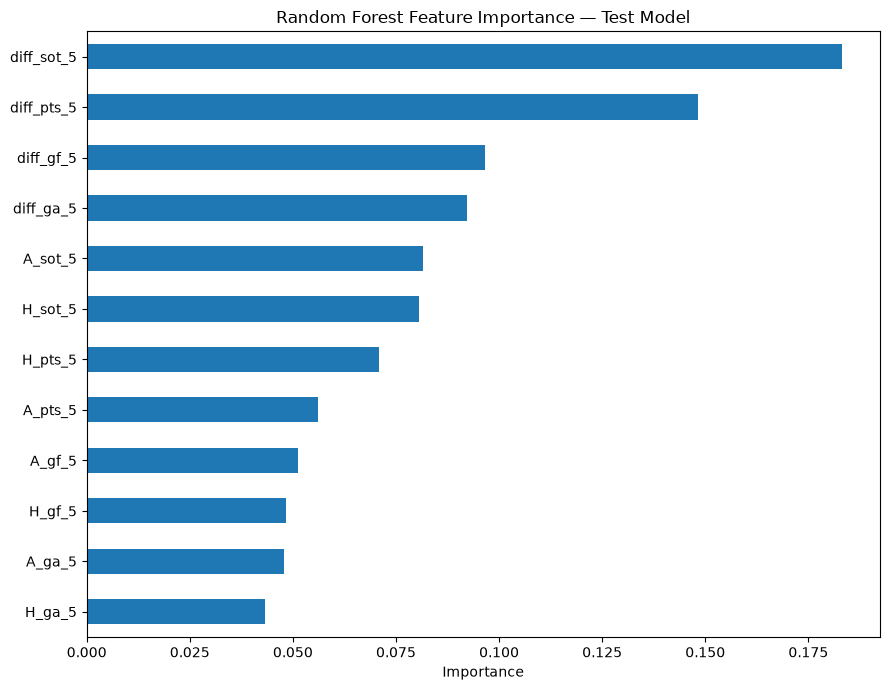

,class_A,class_D,class_H
H_gf_5,-0.0319,-0.0030,0.0349
H_ga_5,0.0116,0.0292,-0.0408
H_pts_5,-0.0798,0.0337,0.0461
H_sot_5,-0.0581,-0.0390,0.0972
A_gf_5,0.0459,-0.0256,-0.0203
A_ga_5,-0.0786,0.0077,0.0709
A_pts_5,-0.0344,0.0296,0.0048
A_sot_5,0.0865,-0.0255,-0.0610
diff_gf_5,-0.0556,0.0161,0.0395
diff_ga_5,0.0660,0.0156,-0.0815


In [15]:
# 9. Feature importance Random Forest
rf_classifier = evaluation_model_rf.named_steps["classifier"]
feature_importance = pd.Series(
    rf_classifier.feature_importances_, index=FEATURE_COLUMNS, name="importance"
).sort_values(ascending=True)

display(feature_importance.sort_values(ascending=False).to_frame())

ax = feature_importance.plot(kind="barh", figsize=(9, 7), title="Random Forest Feature Importance — Test Model")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(REPORT_DIR / "feature_importance_random_forest.png", dpi=160, bbox_inches="tight")
plt.show()

# Koefisien Logistic Regression (Pipeline multi-class)
lr_classifier = evaluation_model_lr.named_steps["classifier"]
lr_coefficients = pd.DataFrame(
    lr_classifier.coef_.T,
    index=FEATURE_COLUMNS,
    columns=[f"class_{label}" for label in lr_classifier.classes_],
)
display(lr_coefficients.round(4))
lr_coefficients.to_csv(REPORT_DIR / "logistic_regression_coefficients.csv")

## 10. Melatih dan membekukan model produksi 2026/27

Model produksi berbeda dari model yang dipakai melaporkan final test. Setelah hasil test 2025/26 dilaporkan, model produksi dilatih ulang menggunakan seluruh data sampai musim 2025/26 (train + validation + test). Model ini kemudian dibekukan untuk prediksi musim 2026/27. Data musim 2026/27 tidak digunakan untuk melatih model produksi.

In [16]:
# 10. Production models: training sampai akhir musim 2025/26, lalu freeze
production_data = pd.concat([train, valid, test], ignore_index=True).sort_values("Date", kind="stable")
X_production = production_data[FEATURE_COLUMNS]
y_production = production_data["Target"]

production_model_lr = make_lr_model(best_params_lr)
production_model_rf = make_rf_model(best_params_rf)

production_model_lr.fit(X_production, y_production)
production_model_rf.fit(X_production, y_production)

# Simpan pipeline utuh: imputer + scaler (LR) + classifier.
joblib.dump(production_model_lr, ARTIFACT_DIR / "model_lr.joblib")
joblib.dump(production_model_rf, ARTIFACT_DIR / "model_rf.joblib")

with open(ARTIFACT_DIR / "feature_columns.json", "w", encoding="utf-8") as f:
    json.dump(FEATURE_COLUMNS, f, indent=2)

model_metadata = {
    "model_version": "epl-result-live-2026-2027-v1",
    "target_classes": CLASS_ORDER,
    "feature_columns": FEATURE_COLUMNS,
    "feature_count": len(FEATURE_COLUMNS),
    "history_window_matches": HISTORY_WINDOW,
    "minimum_history_matches": MIN_HISTORY_MATCHES,
    "history_venue_policy": "all_home_and_away_matches",
    "same_calendar_date_policy": "exclude_same_date_matches_from_prior_history",
    "sot_missing_policy": "mean_of_valid_sot_in_last_five; median_imputation_fitted_inside_training_pipeline",
    "training_seasons": TRAIN_SEASONS + VALID_SEASONS + TEST_SEASONS,
    "training_through_season": "2025/2026",
    "live_season": "2026/2027",
    "model_is_frozen_for_live_season": True,
    "random_state": RANDOM_STATE,
    "selected_parameters": {
        "logistic_regression": best_params_lr,
        "random_forest": best_params_rf,
    },
}

with open(ARTIFACT_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=2)

# Daftar tim yang muncul pada data musim 2026/27 yang sudah tersedia saat CSV dikumpulkan.
teams_live = sorted(
    set(data.loc[data["Season"].isin(LIVE_SEASONS), "HomeTeam"].dropna().tolist())
    | set(data.loc[data["Season"].isin(LIVE_SEASONS), "AwayTeam"].dropna().tolist())
)
with open(ARTIFACT_DIR / "teams_active.json", "w", encoding="utf-8") as f:
    json.dump(teams_live, f, indent=2)

print("Production artifacts saved:")
for filename in ["model_lr.joblib", "model_rf.joblib", "feature_columns.json", "model_metadata.json", "teams_active.json"]:
    print("-", ARTIFACT_DIR / filename)
print("Production training rows:", len(production_data))
print("Production classes LR:", production_model_lr.named_steps["classifier"].classes_)
print("Production classes RF:", production_model_rf.named_steps["classifier"].classes_)

Production artifacts saved:
- D:\Skripsi\epl-prediction-system\ml-service\artifacts\model_lr.joblib
- D:\Skripsi\epl-prediction-system\ml-service\artifacts\model_rf.joblib
- D:\Skripsi\epl-prediction-system\ml-service\artifacts\feature_columns.json
- D:\Skripsi\epl-prediction-system\ml-service\artifacts\model_metadata.json
- D:\Skripsi\epl-prediction-system\ml-service\artifacts\teams_active.json
Production training rows: 2980
Production classes LR: ['A' 'D' 'H']
Production classes RF: ['A' 'D' 'H']


In [17]:
# Production model verification

print("Model LR:", type(production_model_lr).__name__)
print("Model RF:", type(production_model_rf).__name__)

print(
    "LR feature count:",
    production_model_lr.named_steps["classifier"].n_features_in_
)

print(
    "RF feature count:",
    production_model_rf.named_steps["classifier"].n_features_in_
)

print("Feature columns:", len(FEATURE_COLUMNS))
print("Model version:", model_metadata["model_version"])
print("Frozen:", model_metadata["model_is_frozen_for_live_season"])

assert len(FEATURE_COLUMNS) == 12
assert production_model_lr.named_steps["classifier"].n_features_in_ == 12
assert production_model_rf.named_steps["classifier"].n_features_in_ == 12
assert model_metadata["model_is_frozen_for_live_season"] is True

print("\nPRODUCTION MODEL VERIFIED")

Model LR: Pipeline
Model RF: Pipeline
LR feature count: 12
RF feature count: 12
Feature columns: 12
Model version: epl-result-live-2026-2027-v1
Frozen: True

PRODUCTION MODEL VERIFIED


## 11. Membentuk fitur untuk fixture mendatang

Fungsi berikut dipakai untuk fixture yang belum berlangsung. `historical_matches` harus berisi pertandingan yang telah selesai (skor tersedia). Fitur hanya mengambil pertandingan pada tanggal kalender yang lebih awal dari tanggal kickoff. Pertandingan pada tanggal kickoff yang sama dikecualikan sebagai aturan konservatif karena data sumber tidak menyediakan waktu selesai yang dapat diverifikasi. Fungsi ini tidak membuat evaluasi live retrospektif; prediksi nyata harus disimpan oleh aplikasi sebelum kickoff.

In [11]:
# 11. Helper untuk membangun fitur satu fixture berdasarkan tanggal kickoff

def get_team_history_before(team_name, cutoff_date, historical_matches):
    cutoff_date = pd.to_datetime(cutoff_date).normalize()
    prior_matches = historical_matches[historical_matches["Date"] < cutoff_date]

    home_rows = prior_matches[prior_matches["HomeTeam"] == team_name]
    away_rows = prior_matches[prior_matches["AwayTeam"] == team_name]

    team_games = []
    for row in home_rows.itertuples(index=False):
        points = 3 if row.FTHG > row.FTAG else (1 if row.FTHG == row.FTAG else 0)
        team_games.append({"Date": row.Date, "GF": row.FTHG, "GA": row.FTAG, "Points": points, "SOT": row.HST})

    for row in away_rows.itertuples(index=False):
        points = 3 if row.FTAG > row.FTHG else (1 if row.FTAG == row.FTHG else 0)
        team_games.append({"Date": row.Date, "GF": row.FTAG, "GA": row.FTHG, "Points": points, "SOT": row.AST})

    team_games = sorted(team_games, key=lambda item: item["Date"])[-HISTORY_WINDOW:]
    if len(team_games) < MIN_HISTORY_MATCHES:
        raise ValueError(
            f"Riwayat {team_name} hanya {len(team_games)} pertandingan sebelum {cutoff_date.date()}; "
            f"minimal {MIN_HISTORY_MATCHES} diperlukan."
        )

    valid_sot = [item["SOT"] for item in team_games if pd.notna(item["SOT"])]
    return {
        "gf_5": float(np.mean([item["GF"] for item in team_games])),
        "ga_5": float(np.mean([item["GA"] for item in team_games])),
        "pts_5": float(np.mean([item["Points"] for item in team_games])),
        "sot_5": float(np.mean(valid_sot)) if valid_sot else np.nan,
    }


def build_fixture_feature_row(home_team, away_team, kickoff_date, historical_matches):
    if home_team == away_team:
        raise ValueError("Tim kandang dan tandang harus berbeda.")

    cutoff = pd.to_datetime(kickoff_date).normalize()
    home_stats = get_team_history_before(home_team, cutoff, historical_matches)
    away_stats = get_team_history_before(away_team, cutoff, historical_matches)

    row = {}
    for suffix in FEATURE_SUFFIXES:
        h_value = home_stats[suffix]
        a_value = away_stats[suffix]
        row[f"H_{suffix}"] = h_value
        row[f"A_{suffix}"] = a_value
        row[f"diff_{suffix}"] = (
            h_value - a_value if pd.notna(h_value) and pd.notna(a_value) else np.nan
        )

    return pd.DataFrame([row], columns=FEATURE_COLUMNS)


def predict_fixture(home_team, away_team, kickoff_date, historical_matches=data):
    """Hasil probabilitas dua model dalam urutan H, D, A."""
    X_fixture = build_fixture_feature_row(
        home_team, away_team, kickoff_date, historical_matches
    )
    lr_prob = predict_proba_in_class_order(production_model_lr, X_fixture)[0]
    rf_prob = predict_proba_in_class_order(production_model_rf, X_fixture)[0]

    return {
        "home_team": home_team,
        "away_team": away_team,
        "kickoff_date": str(pd.to_datetime(kickoff_date).date()),
        "feature_count": len(FEATURE_COLUMNS),
        "history_window": HISTORY_WINDOW,
        "minimum_history_matches": MIN_HISTORY_MATCHES,
        "probabilities": {
            "logistic_regression": dict(zip(CLASS_ORDER, np.round(lr_prob, 6).tolist())),
            "random_forest": dict(zip(CLASS_ORDER, np.round(rf_prob, 6).tolist())),
        },
        "model_version": model_metadata["model_version"],
    }

print("Fixture prediction helper siap. Contoh pemakaian:")
print("predict_fixture('Arsenal', 'Chelsea', '2026-11-15')")
print("Jalankan contoh hanya jika kedua tim memiliki minimal 3 laga sebelum tanggal tersebut.")

Fixture prediction helper siap. Contoh pemakaian:
predict_fixture('Arsenal', 'Chelsea', '2026-11-15')
Jalankan contoh hanya jika kedua tim memiliki minimal 3 laga sebelum tanggal tersebut.


In [18]:
prediction = predict_fixture(
    'Arsenal',
    'Chelsea',
    '2026-11-15'
)

print(prediction)

{'home_team': 'Arsenal', 'away_team': 'Chelsea', 'kickoff_date': '2026-11-15', 'feature_count': 12, 'history_window': 5, 'minimum_history_matches': 3, 'probabilities': {'logistic_regression': {'H': 0.40889, 'D': 0.334658, 'A': 0.256452}, 'random_forest': {'H': 0.386105, 'D': 0.313836, 'A': 0.300059}}, 'model_version': 'epl-result-live-2026-2027-v1'}


## 12. Ringkasan dan keluaran

Notebook ini tidak menghitung akurasi live 2026/27 dari seluruh baris pertandingan yang sudah selesai. Evaluasi live harus menggunakan prediksi yang telah direkam oleh sistem sebelum kickoff dan baru dinilai setelah hasil aktual tersedia.

In [12]:
# 12. Simpan ringkasan eksperimen dan tampilkan lokasi keluaran
experiment_summary = {
    "feature_count": len(FEATURE_COLUMNS),
    "feature_columns": FEATURE_COLUMNS,
    "train_rows": len(train),
    "validation_rows": len(valid),
    "test_rows": len(test),
    "live_completed_rows_not_used_as_retrospective_live_evaluation": len(live_completed),
    "best_lr_params": best_params_lr,
    "best_rf_params": best_params_rf,
    "test_metrics": test_metrics.to_dict(orient="records"),
    "production_model_version": model_metadata["model_version"],
}

with open(REPORT_DIR / "experiment_summary.json", "w", encoding="utf-8") as f:
    json.dump(experiment_summary, f, indent=2, default=str)

print("\n=== EKSPERIMEN SELESAI ===")
print("Artefak:", ARTIFACT_DIR)
print("Laporan:", REPORT_DIR)
print("Dataset fitur:", PROCESSED_DIR / "match_features_12.csv")
display(test_metrics.round(4))


=== EKSPERIMEN SELESAI ===
Artefak: D:\Skripsi\epl-prediction-system\ml-service\artifacts
Laporan: D:\Skripsi\epl-prediction-system\ml-service\artifacts\reports
Dataset fitur: D:\Skripsi\epl-prediction-system\ml-service\data\processed\match_features_12.csv


,model,accuracy,macro_precision,macro_recall,macro_f1,log_loss
0,Majority baseline,0.4218,0.1406,0.3333,0.1978,1.1211
1,Logistic Regression,0.4085,0.3852,0.3938,0.3859,1.2086
2,Random Forest,0.4005,0.3895,0.3923,0.3877,1.2078
